# 🍚 Exploratory Data Analysis (EDA): Prevalensi Ketidakcukupan Konsumsi Pangan (PoU) Kabupaten/Kota di Indonesia (2017–2025)

**Mata Kuliah:** Presentasi dan Storytelling Data  
**Topik:** Evaluasi Pencapaian SDG 2.1.1 (Tanpa Kelaparan / Zero Hunger) Tingkat Kabupaten/Kota  
**Dataset:** `dataset_pou/` (9 Berkas CSV Rilis Tahunan BPS 2017–2025)  

---

## 📌 1. Latar Belakang & Konteks Analisis
**Prevalence of Undernourishment (PoU)** atau **Prevalensi Ketidakcukupan Konsumsi Pangan** adalah indikator baku internasional yang diadopsi oleh PBB dan FAO dalam kerangka **Tujuan Pembangunan Berkelanjutan (SDGs) Target 2.1.1**: *Menghilangkan kelaparan dan menjamin akses bagi semua orang terhadap makanan yang aman, bergizi, dan cukup sepanjang tahun.*

Berdasarkan metodologi Badan Pusat Statistik (BPS) dan FAO:
- **Definisi:** PoU mengukur persentase populasi di suatu wilayah yang asupan konsumsi energi hariannya (dihitung dari Survei Sosial Ekonomi Nasional / Susenas) berada di bawah **Kebutuhan Energi Minimum (Minimum Dietary Energy Requirement - MDER)** yang dibutuhkan untuk hidup sehat dan aktif.
- **Signifikansi:** Berbeda dengan kemiskinan yang mengukur pengeluaran moneter, PoU mengukur secara langsung **defisit asupan kalori/energi biologis**. Seseorang bisa saja tidak tergolong miskin secara moneter, namun tetap mengalami ketidakcukupan konsumsi pangan karena keterbatasan pasokan fisik, mahalnya harga komoditas pangan sehat, atau pola konsumsi yang buruk.

Notebook ini menggabungkan dan menganalisis 9 berkas CSV tahunan (2017–2025) yang mencakup **514 kabupaten dan kota di seluruh Indonesia**, mengungkap dinamika kelaparan kronis, dampak krisis pangan global 2022, serta mengidentifikasi kantong-kantong kerawanan gizi yang mendesak untuk diintervensi.


In [1]:
# Setup library analisis data & visualisasi
import os
import glob
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi estetika visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.autolayout'] = True
sns.set_palette('tab10')

print("✅ Library analisis berhasil dimuat!")


✅ Library analisis berhasil dimuat!


## 🧹 2. Pemuatan & Konsolidasi Data Multi-Tahun (Data Ingestion & Panel Building)

Dataset `dataset_pou` terdiri dari 9 berkas CSV terpisah untuk setiap tahun (2017 hingga 2025). 
Setiap berkas memiliki metadata tabel BPS pada 3 baris awal (header judul dan tahun rilis), diikuti 514 baris data wilayah.

Langkah pembersihan data:
1. Membaca setiap CSV dengan `skiprows=3`.
2. Mengekstrak tahun dari nama berkas menggunakan ekspresi reguler (*regex*).
3. Memastikan konversi nilai persentase PoU menjadi tipe numerik (`float64`).
4. Membangun dua struktur data:
   - **`df_pou_panel` (Long Format):** 4.626 baris observasi (514 daerah x 9 tahun) untuk analisis tren dan distribusi.
   - **`df_pou_wide` (Wide Format):** Matriks 514 daerah x 9 kolom tahun untuk analisis delta perubahan dan korelasi.


In [2]:
# Mengumpulkan seluruh berkas CSV PoU
raw_data_dir = os.path.join('..', 'data', 'raw') if os.path.exists(os.path.join('..', 'data', 'raw')) else (os.path.join('data', 'raw') if os.path.exists(os.path.join('data', 'raw')) else '.')
pou_files = sorted(glob.glob(os.path.join(raw_data_dir, 'dataset_pou', '*.csv')))
print(f"Ditemukan {len(pou_files)} berkas CSV di folder dataset_pou:")

dfs_long = []
dfs_wide = []

for f in pou_files:
    # Ekstrak tahun dari nama file
    match = re.search(r'(\d{4})', os.path.basename(f))
    year = int(match.group(1))
    
    # Baca data dengan skiprows=3
    df_temp = pd.read_csv(f, skiprows=3, names=['kabupaten_kota', 'pou'], encoding='utf-8')
    df_temp['kabupaten_kota'] = df_temp['kabupaten_kota'].str.strip()
    df_temp['pou'] = pd.to_numeric(df_temp['pou'], errors='coerce')
    df_temp['tahun'] = year
    
    # Simpan ke list long
    dfs_long.append(df_temp)
    
    # Siapkan untuk wide
    dfs_wide.append(df_temp.set_index('kabupaten_kota')[['pou']].rename(columns={'pou': f'pou_{year}'}))

# 1. Bentuk DataFrame Long Panel
df_pou_panel = pd.concat(dfs_long, ignore_index=True)

# 2. Bentuk DataFrame Wide Matriks
df_pou_wide = pd.concat(dfs_wide, axis=1).reset_index()

# 3. Klasifikasi Kategori Kerentanan PoU Berdasarkan Standar FAO/BPS
bins = [0, 5, 10, 20, 35, 100]
labels = [
    '1. Sangat Rendah (< 5%)',
    '2. Rendah (5 - 10%)',
    '3. Sedang/Waspada (10 - 20%)',
    '4. Tinggi (20 - 35%)',
    '5. Sangat Tinggi/Kritis (> 35%)'
]
df_pou_panel['kategori_pou'] = pd.cut(df_pou_panel['pou'], bins=bins, labels=labels)

print(f"Master Long Panel: {df_pou_panel.shape[0]} baris x {df_pou_panel.shape[1]} kolom")
print(f"Master Wide Data : {df_pou_wide.shape[0]} kabupaten/kota x {df_pou_wide.shape[1]} kolom")
print(f"Missing Values   : {df_pou_panel['pou'].isnull().sum()} (100% data lengkap)")


Ditemukan 9 berkas CSV di folder dataset_pou:


Master Long Panel: 4626 baris x 4 kolom
Master Wide Data : 514 kabupaten/kota x 10 kolom
Missing Values   : 0 (100% data lengkap)


## 📊 3. Struktur Data & Statistik Ringkasan (Data Profiling)

Mari kita telaah parameter statistik utama prevalensi ketidakcukupan pangan nasional sepanjang periode 2017–2025.


In [3]:
# Statistik Deskriptif PoU Tahunan
stats_yearly = df_pou_panel.groupby('tahun')['pou'].agg(
    jumlah_daerah='count',
    rerata='mean',
    median='median',
    standar_deviasi='std',
    minimum='min',
    maksimum='max',
    kuartil_1=lambda x: x.quantile(0.25),
    kuartil_3=lambda x: x.quantile(0.75)
).reset_index()

stats_yearly['iqr'] = stats_yearly['kuartil_3'] - stats_yearly['kuartil_1']

print("=== STATISTIK RINGKASAN PoU TAHUNAN (2017–2025) ===")
display(stats_yearly.round(2))


=== STATISTIK RINGKASAN PoU TAHUNAN (2017–2025) ===


,tahun,jumlah_daerah,rerata,median,standar_deviasi,minimum,maksimum,kuartil_1,kuartil_3,iqr
0,2017,514,11.46,8.37,10.45,0.59,69.70,5.67,12.92,7.25
1,2018,514,11.42,8.16,10.67,0.86,65.69,5.30,12.65,7.35
2,2019,514,11.26,8.23,11.00,0.74,83.57,4.97,11.78,6.81
3,2020,514,11.63,9.06,9.74,0.91,72.20,5.94,12.63,6.68
4,2021,514,11.95,9.29,10.45,0.94,79.67,6.10,13.03,6.93
5,2022,514,13.75,11.36,9.93,0.83,80.32,7.40,15.91,8.50
6,2023,514,12.06,9.19,9.70,0.65,67.17,6.75,13.43,6.68
7,2024,514,11.08,8.69,8.73,0.87,57.91,6.20,12.34,6.14
8,2025,514,10.75,8.38,8.42,1.16,59.17,5.92,11.84,5.92


## 📈 4. Analisis Tren Temporal PoU Nasional (2017–2025)

Pertanyaan Storytelling:
1. Bagaimana tren prevalensi ketidakcukupan konsumsi pangan nasional berkembang selama 9 tahun?
2. Mengapa terjadi lonjakan tajam pada tahun **2022**?
   - *Konteks Makro:* Tahun 2022 diwarnai lonjakan inflasi pangan dan pupuk global akibat konflik geopolitik Rusia-Ukraina, gangguan rantai pasok global, dan penyesuaian harga BBM bersubsidi domestik.
3. Apakah kondisi pangan telah pulih pada periode 2023–2025?


findfont: Failed to find font weight semibold, now using 700.


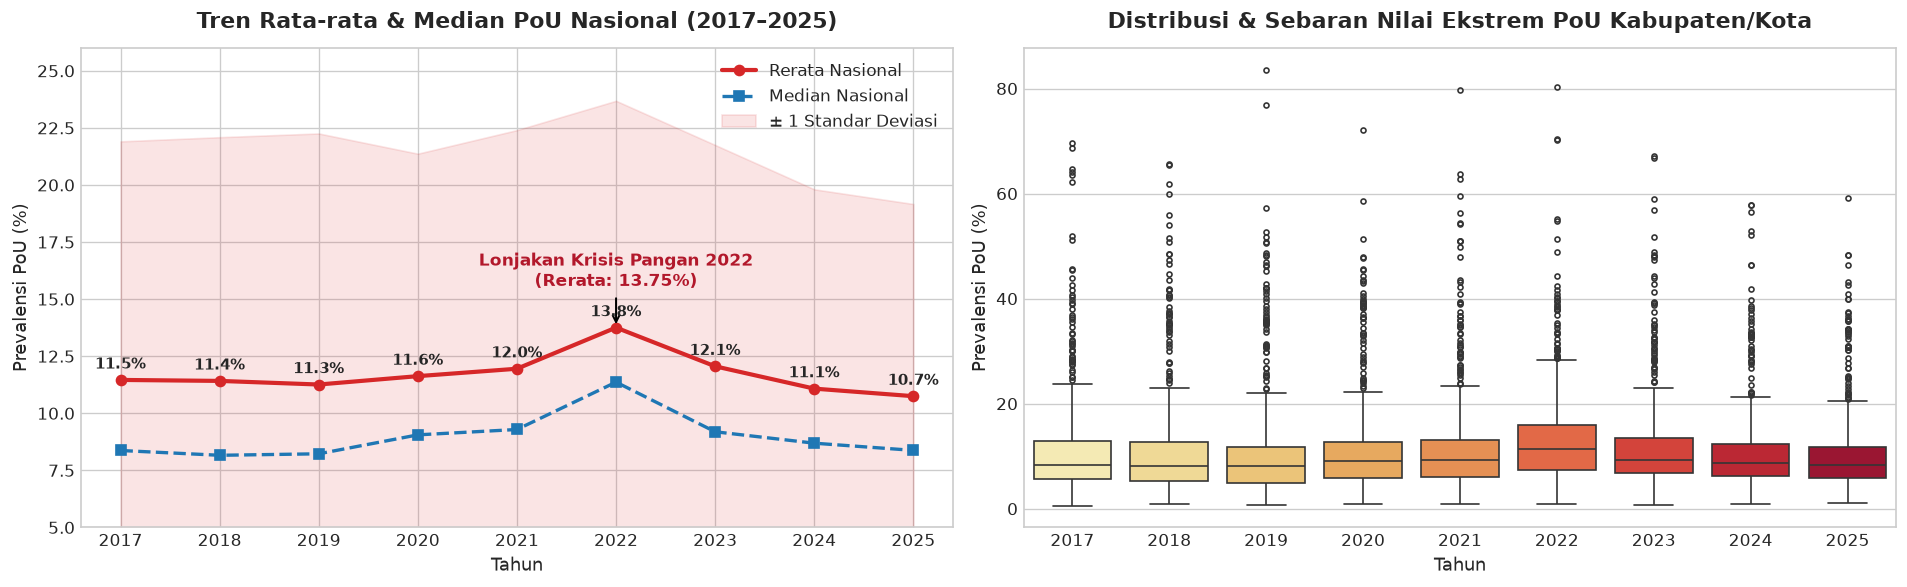

In [4]:
# Visualisasi Tren Temporal PoU Nasional
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Line plot Rerata & Median
axes[0].plot(stats_yearly['tahun'], stats_yearly['rerata'], marker='o', linewidth=2.5, color='#d62728', label='Rerata Nasional')
axes[0].plot(stats_yearly['tahun'], stats_yearly['median'], marker='s', linewidth=2.0, color='#1f77b4', linestyle='--', label='Median Nasional')
axes[0].fill_between(stats_yearly['tahun'], stats_yearly['rerata'] - stats_yearly['standar_deviasi'], 
                     stats_yearly['rerata'] + stats_yearly['standar_deviasi'], color='#d62728', alpha=0.12, label='± 1 Standar Deviasi')

axes[0].set_title('Tren Rata-rata & Median PoU Nasional (2017–2025)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Tahun', fontsize=11)
axes[0].set_ylabel('Prevalensi PoU (%)', fontsize=11)
axes[0].set_ylim(5, 26)
axes[0].legend(loc='upper right')

# Anotasi lonjakan 2022
peak_val = stats_yearly.loc[stats_yearly['tahun'] == 2022, 'rerata'].values[0]
axes[0].annotate(f"Lonjakan Krisis Pangan 2022\n(Rerata: {peak_val:.2f}%)", (2022, peak_val),
                 xytext=(0, 25), textcoords='offset points', ha='center',
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.2), fontweight='bold', color='#b2182b')

for idx, r in stats_yearly.iterrows():
    axes[0].text(r['tahun'], r['rerata'] + 0.5, f"{r['rerata']:.1f}%", ha='center', fontsize=9, fontweight='semibold')

# Plot 2: Boxplot Sebaran PoU Antar-Tahun
sns.boxplot(data=df_pou_panel, x='tahun', y='pou', palette='YlOrRd', ax=axes[1], fliersize=3)
axes[1].set_title('Distribusi & Sebaran Nilai Ekstrem PoU Kabupaten/Kota', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Tahun', fontsize=11)
axes[1].set_ylabel('Prevalensi PoU (%)', fontsize=11)

plt.tight_layout()
plt.show()


## 🌊 5. Pergeseran Kurva Distribusi PoU (KDE Density Plots)

Distribusi PoU memiliki karakteristik **positive skewness (kemencengan ke kanan)** yang sangat kuat. Mayoritas kabupaten/kota terkonsentrasi pada angka di bawah 15%, namun ada 'ekor panjang' (*long tail*) daerah-daerah dengan prevalensi di atas 30% hingga mendekati 70%–80%.


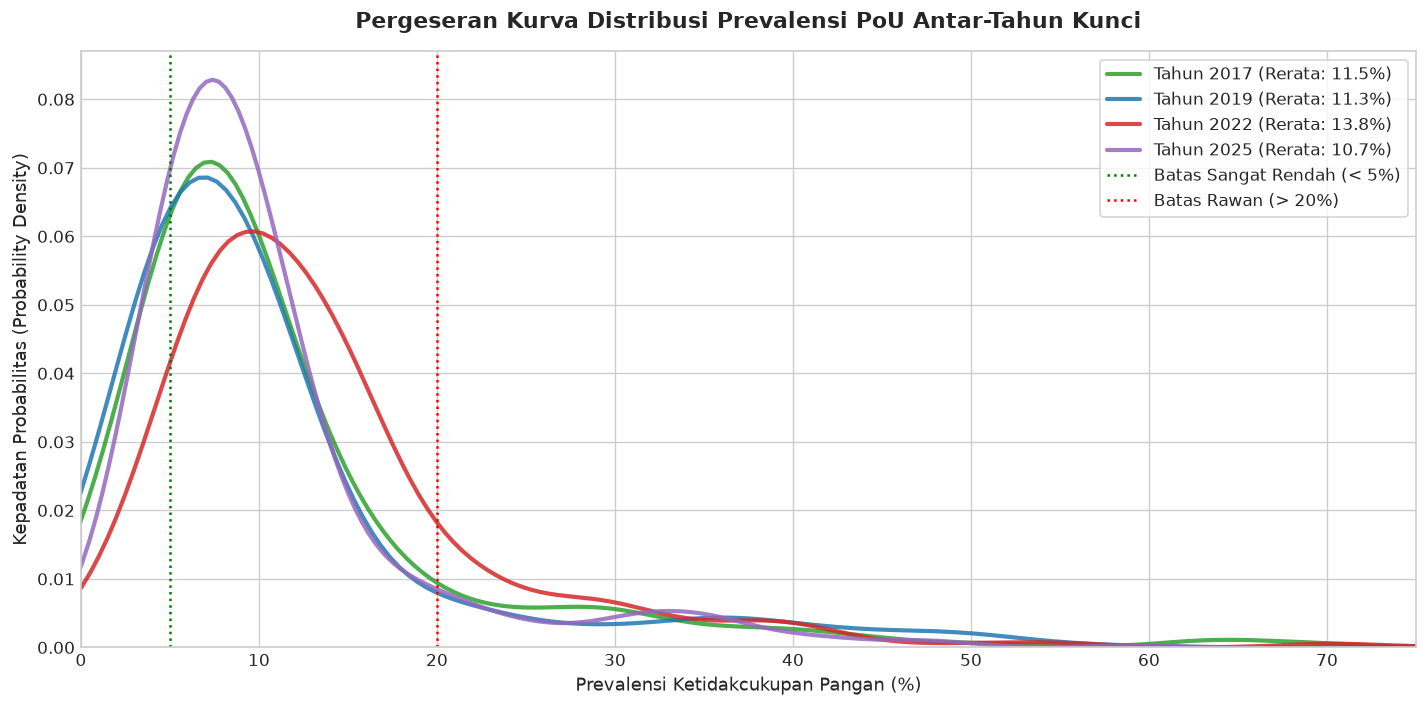

In [5]:
# Kurva Kepadatan Distribusi (KDE) untuk tahun-tahun kunci
selected_years = [2017, 2019, 2022, 2025]
colors_kde = ['#2ca02c', '#1f77b4', '#d62728', '#9467bd']

plt.figure(figsize=(12, 6))
for yr, col in zip(selected_years, colors_kde):
    subset = df_pou_panel[df_pou_panel['tahun'] == yr]
    sns.kdeplot(subset['pou'], label=f'Tahun {yr} (Rerata: {subset["pou"].mean():.1f}%)', 
                color=col, linewidth=2.5, alpha=0.85)

plt.axvline(x=5.0, color='green', linestyle=':', label='Batas Sangat Rendah (< 5%)')
plt.axvline(x=20.0, color='red', linestyle=':', label='Batas Rawan (> 20%)')

plt.title('Pergeseran Kurva Distribusi Prevalensi PoU Antar-Tahun Kunci', fontsize=13, fontweight='bold', pad=14)
plt.xlabel('Prevalensi Ketidakcukupan Pangan (%)', fontsize=11)
plt.ylabel('Kepadatan Probabilitas (Probability Density)', fontsize=11)
plt.xlim(0, 75)
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()


## 🛡️ 6. Dinamika Proporsi Kategori Kerentanan PoU Standar FAO

Bagaimana pergeseran proporsi 514 kabupaten/kota di Indonesia menurut 5 kategori kerentanan pangan internasional?


<Figure size 1680x720 with 0 Axes>

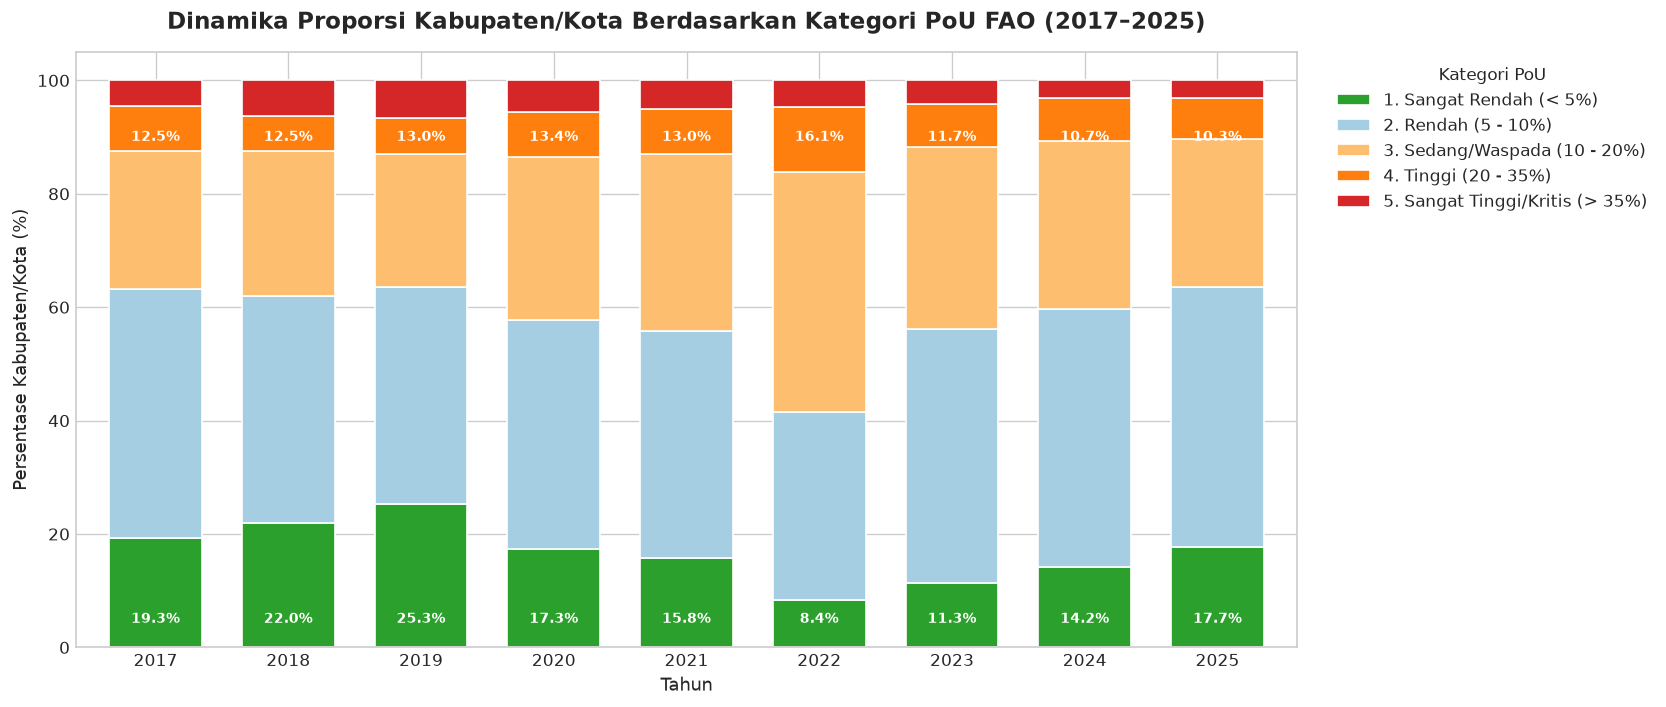

kategori_pou,1. Sangat Rendah (< 5%),2. Rendah (5 - 10%),3. Sedang/Waspada (10 - 20%),4. Tinggi (20 - 35%),5. Sangat Tinggi/Kritis (> 35%)
tahun,,,,,
2017,19.26,43.97,24.32,7.98,4.47
2018,21.98,40.08,25.49,6.23,6.23
2019,25.29,38.33,23.35,6.42,6.61
2020,17.32,40.47,28.79,7.78,5.64
2021,15.76,40.08,31.13,7.98,5.06
2022,8.37,33.07,42.41,11.48,4.67
2023,11.28,44.94,32.10,7.59,4.09
2024,14.20,45.53,29.57,7.59,3.11
2025,17.70,45.91,26.07,7.20,3.11


In [6]:
# Tabel kontinjensi proporsi kategori PoU
crosstab_pou = pd.crosstab(df_pou_panel['tahun'], df_pou_panel['kategori_pou'], normalize='index') * 100

colors_cat = ['#2ca02c', '#a6cee3', '#fdbf6f', '#ff7f0e', '#d62728']

plt.figure(figsize=(14, 6))
ax = crosstab_pou.plot(kind='bar', stacked=True, color=colors_cat, figsize=(14, 6), edgecolor='white', width=0.7)
plt.title('Dinamika Proporsi Kabupaten/Kota Berdasarkan Kategori PoU FAO (2017–2025)', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Tahun', fontsize=11)
plt.ylabel('Persentase Kabupaten/Kota (%)', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Kategori PoU')
plt.xticks(rotation=0)

# Tambahkan persentase kelompok terbaik (<5%) dan terburuk (>20%)
for n, yr in enumerate(crosstab_pou.index):
    sangat_rendah = crosstab_pou.loc[yr, '1. Sangat Rendah (< 5%)']
    kritis = crosstab_pou.loc[yr, ['4. Tinggi (20 - 35%)', '5. Sangat Tinggi/Kritis (> 35%)']].sum()
    ax.text(n, 5, f"{sangat_rendah:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
    ax.text(n, 90, f"{kritis:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)

plt.tight_layout()
plt.show()

display(crosstab_pou.round(2))


## 🏆 7. Pemeringkatan Ekstrem: Daerah Paling Rentan vs Paling Aman Pangan (2025)

Kita mengamati kondisi mutakhir pada tahun **2025** untuk mendeteksi 15 daerah dengan ketidakcukupan konsumsi pangan paling tinggi (zona darurat intervensi) dan 15 daerah dengan ketidakcukupan terendah (zona mandiri pangan).


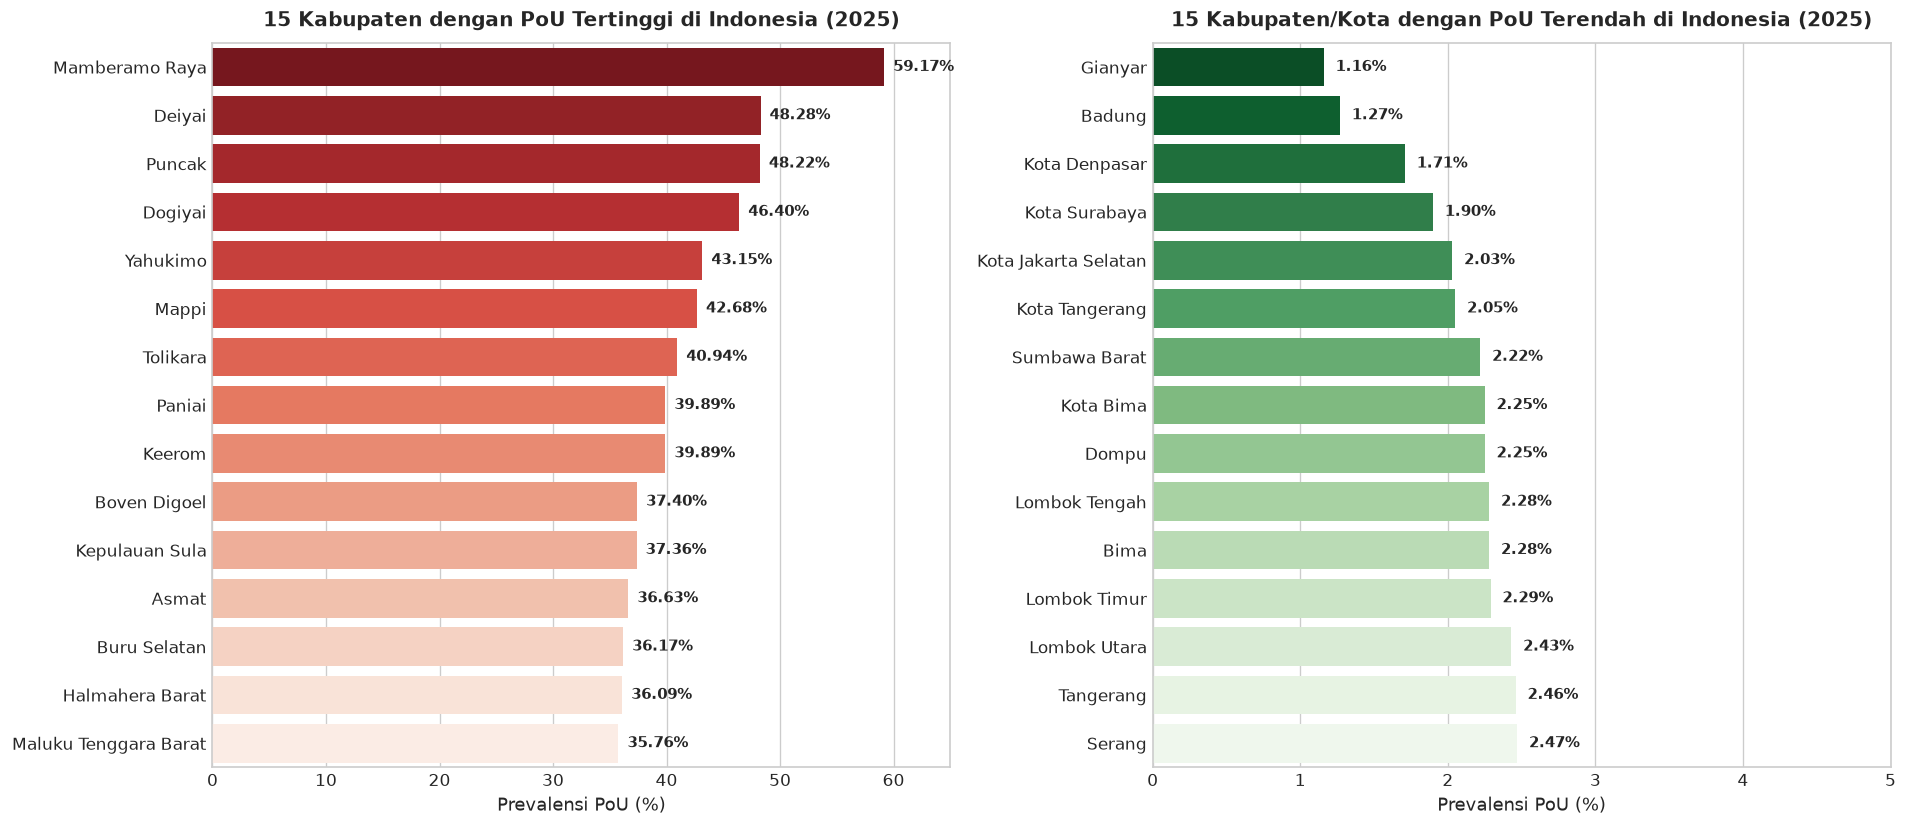

In [7]:
# Pemeringkatan Tahun 2025
df_2025 = df_pou_panel[df_pou_panel['tahun'] == 2025].sort_values('pou', ascending=False)

top15_rawan = df_2025.head(15)
top15_aman = df_2025.tail(15).sort_values('pou', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 15 Rawan
sns.barplot(data=top15_rawan, y='kabupaten_kota', x='pou', palette='Reds_r', ax=axes[0])
axes[0].set_title('15 Kabupaten dengan PoU Tertinggi di Indonesia (2025)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Prevalensi PoU (%)', fontsize=11)
axes[0].set_ylabel('')
axes[0].set_xlim(0, 65)
for i, v in enumerate(top15_rawan['pou']):
    axes[0].text(v + 0.8, i, f"{v:.2f}%", va='center', fontsize=9, fontweight='semibold')

# 15 Aman
sns.barplot(data=top15_aman, y='kabupaten_kota', x='pou', palette='Greens_r', ax=axes[1])
axes[1].set_title('15 Kabupaten/Kota dengan PoU Terendah di Indonesia (2025)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Prevalensi PoU (%)', fontsize=11)
axes[1].set_ylabel('')
axes[1].set_xlim(0, 5)
for i, v in enumerate(top15_aman['pou']):
    axes[1].text(v + 0.08, i, f"{v:.2f}%", va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()


## 🔄 8. Analisis Perubahan & Volatilitas: Kisah Sukses vs Daerah yang Memburuk (2017 vs 2025)

Dengan mengukur delta perubahan $\Delta 	ext{PoU} = 	ext{PoU}_{2025} - 	ext{PoU}_{2017}$, kita dapat mengungkap:
1. **Kisah Sukses (*Success Stories*):** Daerah yang berhasil memangkas defisit pangan warganya secara spektakuler.
2. **Peringatan Dini (*Early Warning Alerts*):** Daerah yang justru mengalami lonjakan drastis angka ketidakcukupan konsumsi pangan.


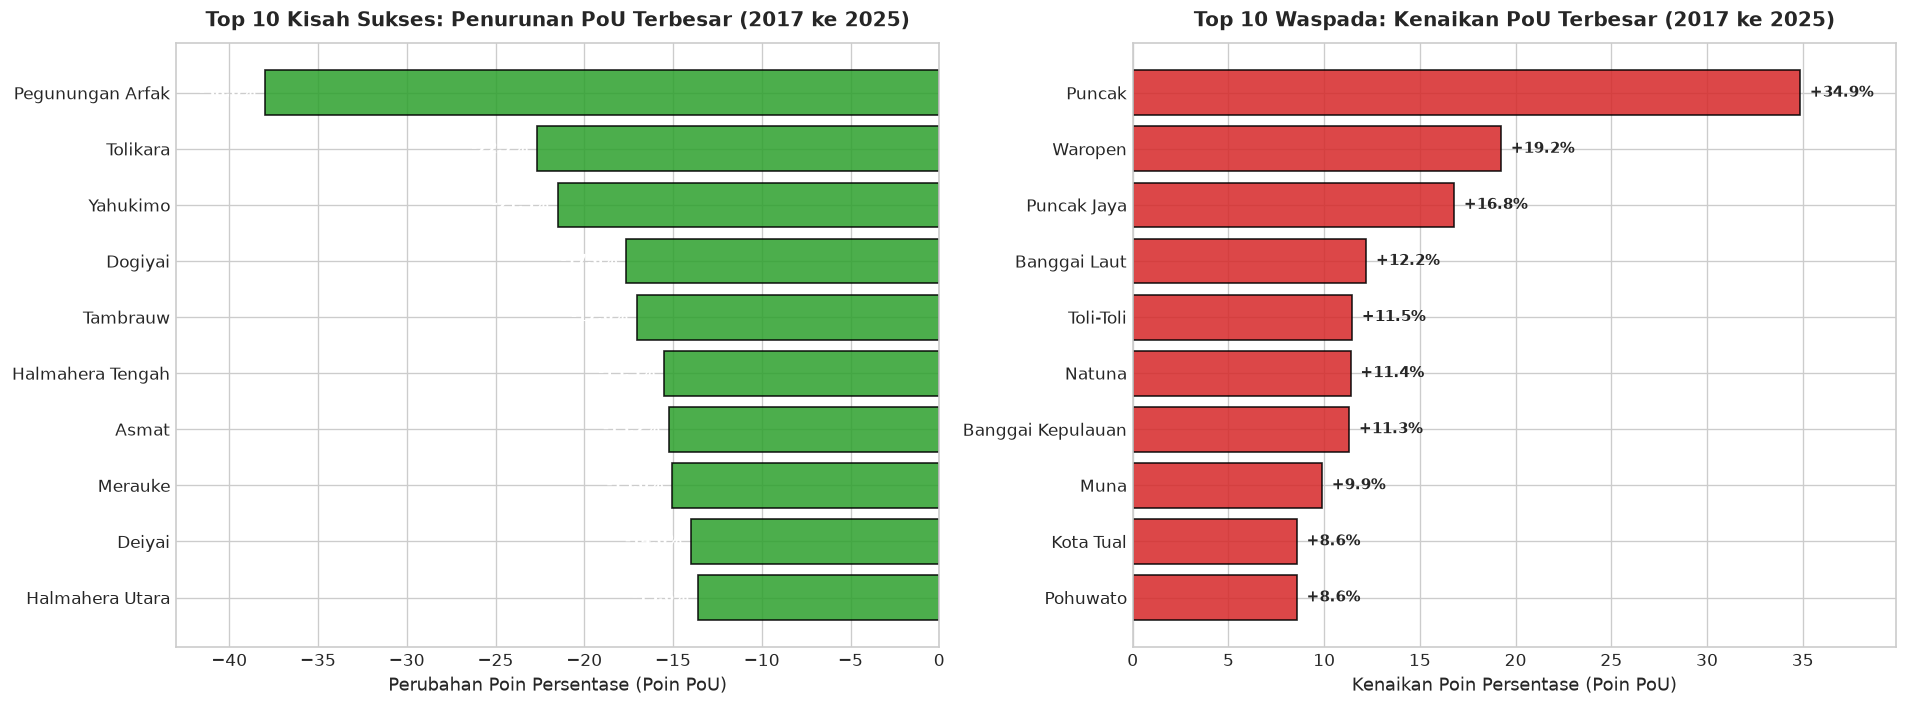

Rincian 5 Daerah dengan Perbaikan Gizi Terbesar:


,kabupaten_kota,pou_2017,pou_2025,delta_total
478,Pegunungan Arfak,68.71,30.71,-38.00
509,Tolikara,63.60,40.94,-22.66
512,Yahukimo,64.65,43.15,-21.50
499,Dogiyai,64.03,46.40,-17.63
483,Tambrauw,39.76,22.72,-17.04
463,Halmahera Tengah,34.54,19.03,-15.51
497,Asmat,51.87,36.63,-15.24
494,Merauke,28.31,13.27,-15.04
500,Deiyai,62.28,48.28,-14.00
466,Halmahera Utara,38.96,25.35,-13.61


In [8]:
# Menghitung delta perubahan 2017 ke 2025
df_pou_wide['delta_total'] = df_pou_wide['pou_2025'] - df_pou_wide['pou_2017']

most_improved = df_pou_wide.sort_values(by='delta_total', ascending=True).head(10)
most_deteriorated = df_pou_wide.sort_values(by='delta_total', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Improved
bars1 = axes[0].barh(most_improved['kabupaten_kota'][::-1], most_improved['delta_total'][::-1], color='#2ca02c', edgecolor='black', alpha=0.85)
axes[0].set_title('Top 10 Kisah Sukses: Penurunan PoU Terbesar (2017 ke 2025)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Perubahan Poin Persentase (Poin PoU)', fontsize=11)
axes[0].set_xlim(min(most_improved['delta_total']) - 5, 0)
for bar in bars1:
    w = bar.get_width()
    axes[0].text(w - 0.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', ha='right', fontsize=9, fontweight='bold', color='white')

# Plot Deteriorated
bars2 = axes[1].barh(most_deteriorated['kabupaten_kota'][::-1], most_deteriorated['delta_total'][::-1], color='#d62728', edgecolor='black', alpha=0.85)
axes[1].set_title('Top 10 Waspada: Kenaikan PoU Terbesar (2017 ke 2025)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Kenaikan Poin Persentase (Poin PoU)', fontsize=11)
axes[1].set_xlim(0, max(most_deteriorated['delta_total']) + 5)
for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 0.5, bar.get_y() + bar.get_height()/2, f"+{w:.1f}%", va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("Rincian 5 Daerah dengan Perbaikan Gizi Terbesar:")
display(most_improved[['kabupaten_kota', 'pou_2017', 'pou_2025', 'delta_total']].round(2))


## 🚨 9. Daerah Rawan Pangan Kronis (*Chronic Hunger Hotspots*)

Wilayah yang secara konsisten memiliki PoU $> 35\%$ selama minimal 7 dari 9 tahun pengamatan mencerminkan masalah defisit energi pangan yang berakar pada isolasi geografis, logistik, dan kemiskinan struktural.


In [9]:
# Identifikasi daerah dengan PoU > 35% persisten
chronic_pou = df_pou_panel[df_pou_panel['pou'] > 35].groupby('kabupaten_kota').agg(
    frekuensi_kritis=('tahun', 'count'),
    rerata_pou=('pou', 'mean'),
    pou_terendah=('pou', 'min'),
    pou_tertinggi=('pou', 'max')
).reset_index()

# Gabungkan dengan nilai PoU 2025 dari df_pou_wide
chronic_pou = chronic_pou.merge(df_pou_wide[['kabupaten_kota', 'pou_2025']], on='kabupaten_kota', how='left')

chronic_pou_top = chronic_pou[chronic_pou['frekuensi_kritis'] >= 7].sort_values(by=['frekuensi_kritis', 'rerata_pou'], ascending=[False, False])

print(f"Total Kabupaten dengan Kelaparan/Defisit Kalori Kronis (≥ 7 tahun di atas 35%): {len(chronic_pou_top)} Daerah")
display(chronic_pou_top.round(2))


Total Kabupaten dengan Kelaparan/Defisit Kalori Kronis (≥ 7 tahun di atas 35%): 17 Daerah


,kabupaten_kota,frekuensi_kritis,rerata_pou,pou_terendah,pou_tertinggi,pou_2025
6,Dogiyai,9,68.55,46.40,83.57,46.40
24,Mamberamo Raya,9,52.87,38.99,69.70,59.17
42,Yahukimo,9,52.00,39.28,64.65,43.15
40,Tolikara,9,50.02,38.37,65.47,40.94
26,Mappi,9,46.22,39.54,56.26,42.68
13,Keerom,9,45.57,37.83,51.33,39.89
34,Sarmi,9,41.82,35.73,51.06,35.73
15,Kepulauan Sula,9,41.15,35.11,46.33,37.36
5,Deiyai,8,62.76,48.28,76.85,48.28
27,Paniai,8,54.16,39.89,70.28,39.89


## 🎯 10. Sintesis Storytelling Data & Rekomendasi Kebijakan

### 💡 Temuan Utama (Key Insights)
1. **Dinamika Agregat & Sensitivitas Krisis 2022:**
   Rata-rata prevalensi ketidakcukupan konsumsi pangan nasional stabil di kisaran **~11,2%–11,5% (2017–2019)**, melonjak tajam ke titik puncak **13,75% pada tahun 2022** akibat kombinasi inflasi pangan global pascapandemi dan kenaikan harga BBM bersubsidi, sebelum akhirnya melandai turun ke **10,75% pada 2025**.
2. **Kesenjangan Asupan Kalori yang Ekstrem:**
   Ketimpangan asupan pangan antar daerah di Indonesia sangat masif:
   - Kabupaten/kota terbaik (didominasi kota-kota di Jawa dan Bali) mencatat PoU hanya **~1,1%–2,0%**.
   - Sebaliknya, daerah rentan di pedalaman Papua (Yahukimo, Tolikara, Dogiyai, Puncak) memiliki PoU berkisar **40% hingga mendekati 60%**. Artinya, separuh lebih warga di daerah tersebut hidup di bawah kebutuhan kalori minimum harian!
3. **Korelasi dengan Geopolitik & Keamanan Daerah:**
   Lonjakan kasus PoU terparah terjadi di Kabupaten Puncak (+34,8 poin) dan Waropen (+19,2 poin), yang erat kaitannya dengan gangguan stabilitas keamanan daerah yang menghambat suplai pesawat perintis kargo sembako.
4. **Bukti Keberhasilan Intervensi Terarah:**
   Kabupaten Pegunungan Arfak, Tolikara, dan Yahukimo membuktikan bahwa dengan percepatan pembangunan infrastruktur perintis dan bantuan pangan, defisit PoU berhasil dipangkas signifikan (turun antara 20 s/d 38 poin persentase).

---

### 📋 Rekomendasi untuk Presentasi & Kebijakan
1. **Penyaluran Bantuan Pangan Berbasis Kalori & Protein Lokal:** Di wilayah pegunungan dan kepulauan terpencil, intervensi bantuan harus mengoptimalkan diversifikasi pangan lokal (umbi-umbian, sagu, ikan) daripada ketergantungan 100% pada beras impor.
2. **Subsidi Ongkos Angkut Logistik Pangan Udara (*Jembatan Udara*):** Mengamankan subsidi penerbangan kargo reguler untuk komoditas pangan pokok ke daerah pedalaman terisolir guna mencegah lonjakan harga ekstrem.
3. **Integrasi Data PoU dengan Program Stunting:** Menjadikan daftar kabupaten/kota PoU kritis sebagai lokus prioritas utama program penanganan gizi buruk dan pencegahan stunting nasional.
